In [2]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import pandas as pd
from astropy.time import Time
import matplotlib.colors as colors
from astropy.timeseries import LombScargle
import matplotlib.dates as mdates
from matplotlib.ticker import LogLocator, LogFormatterMathtext
from matplotlib.colors import LogNorm
import seaborn as sns

# LombScargle Test

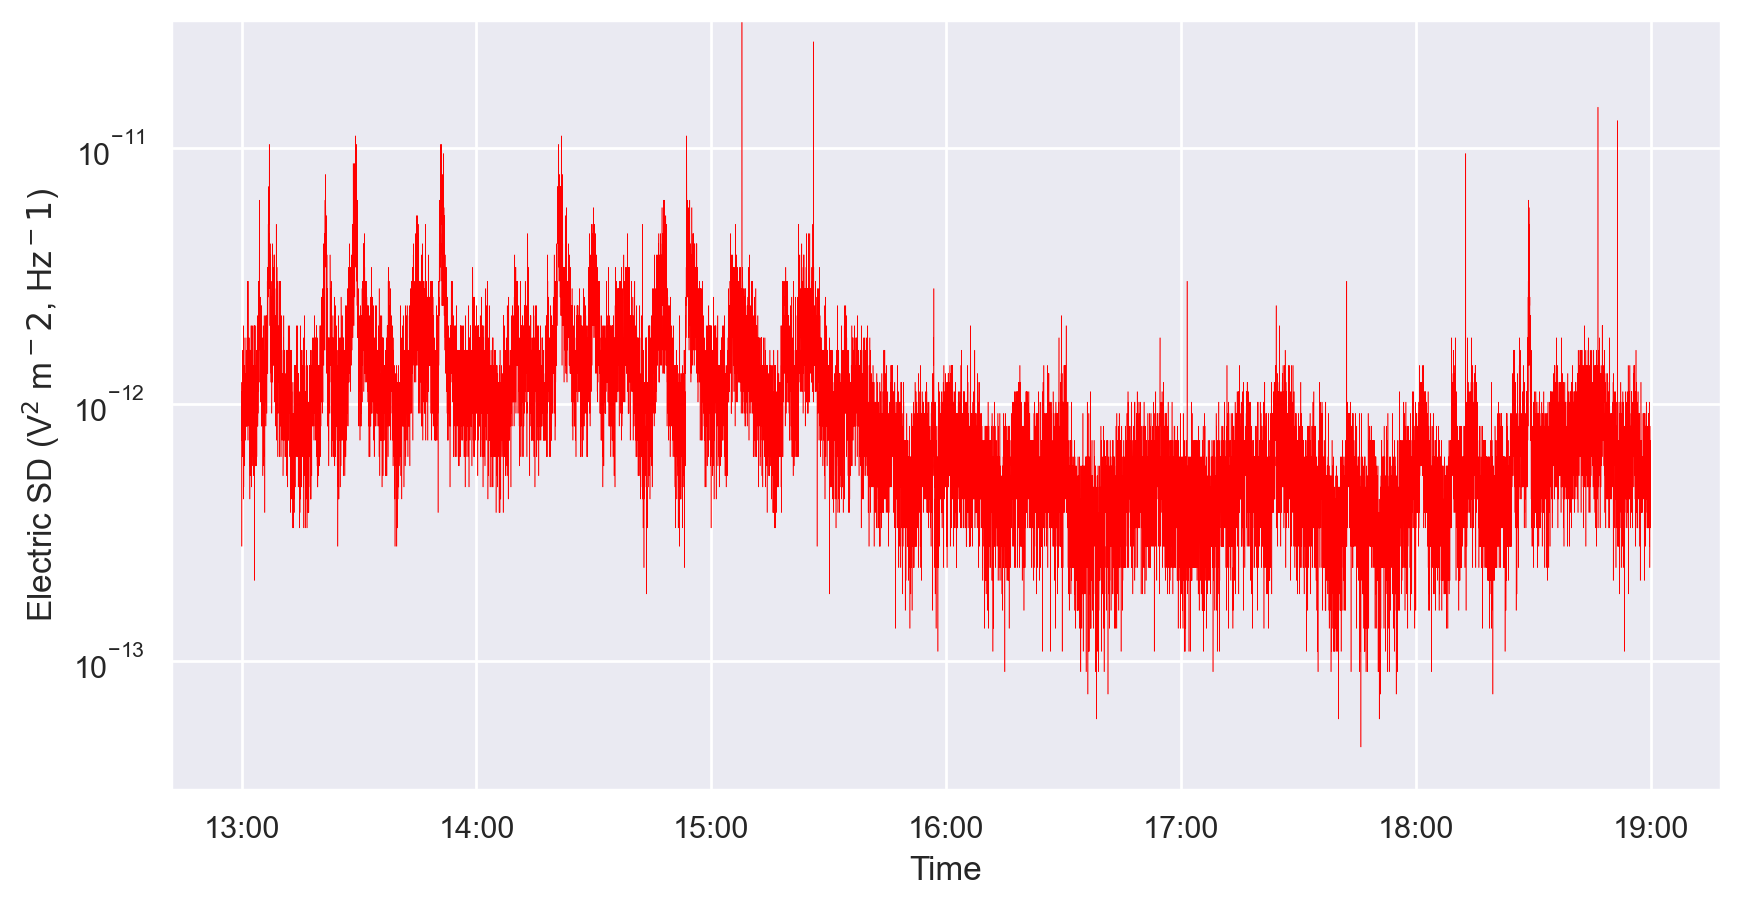

In [17]:
waves = pd.read_csv('JunoWaves20170619_1800_1900.txt', sep=',', skiprows=3)

waves.columns = ['UTC', 'Radio']

waves['UTC'] = waves['UTC'].str[:-1]



times_list = []

for row in waves['UTC']:
    temp_time = Time(row, format='isot').cxcsec
    times_list.append(temp_time)


waves['Time'] = times_list

times_list2 = []
for row in waves['UTC']:
    times_list2.append(Time(row).datetime)

waves['DateTime'] = times_list2



start_time = Time('2017-06-19 13:00').datetime
end_time = Time('2017-06-19 19:00').datetime

waves = waves[(waves['DateTime'] >= start_time) & (waves['DateTime'] <= end_time)]

waves

sns.set_theme(style='darkgrid')

fig, ax = plt.subplots(figsize=(10,5), dpi=200)

plt.plot(waves['DateTime'], waves['Radio'], linewidth=0.2, c='red')
plt.yscale('log')
plt.xlabel('Time')
plt.ylabel(rf'Electric SD (V$^2$ m$^{-2}$, Hz$^{-1}$)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

plt.ylim(10**-13.5, 10**-10.5)
plt.show()

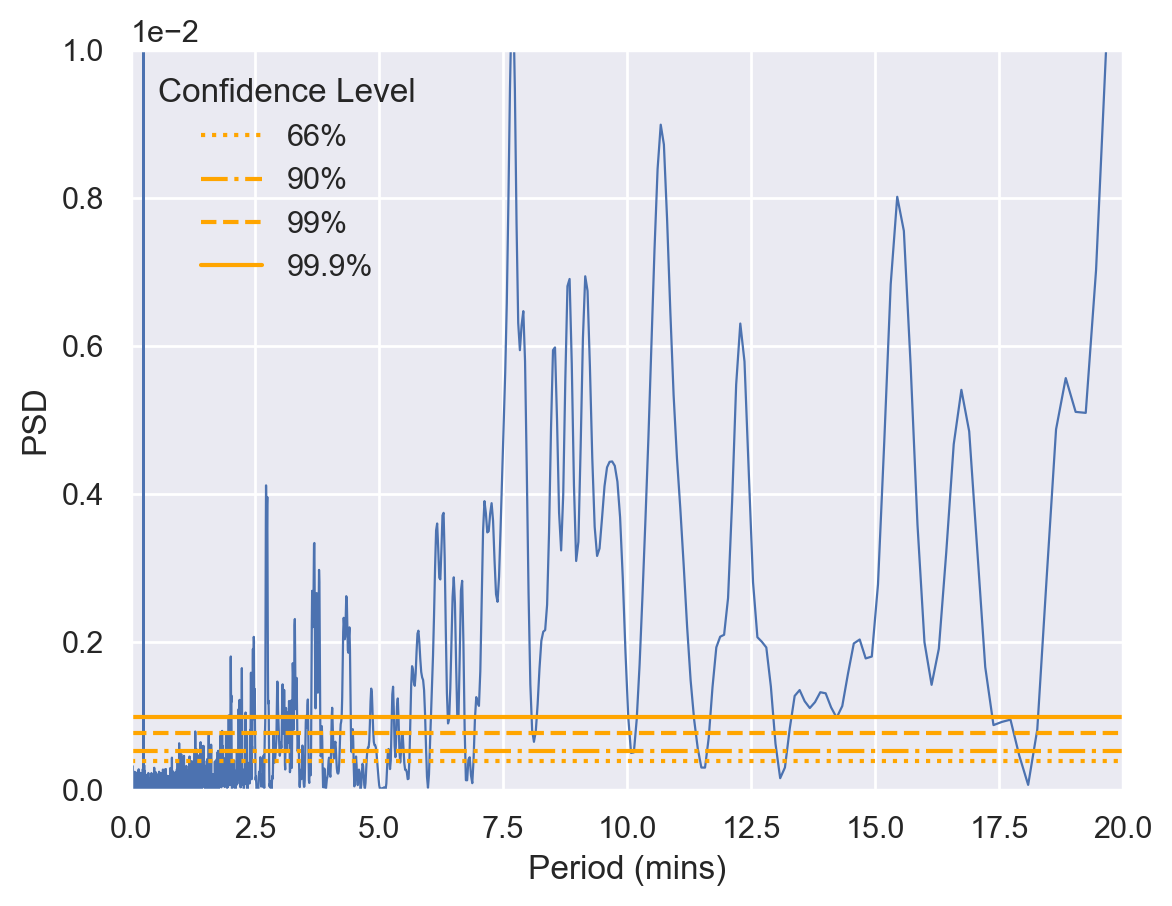

In [41]:
ls = LombScargle(waves.Time, waves.Radio)


frequency_ls, power_ls = ls.autopower()
probabilities = [0.34, 0.1, 0.01, 0.001]
sns.set_theme(style='darkgrid')
fig=plt.figure(dpi=200)

plt.plot((1/frequency_ls/60), power_ls, linewidth=0.8)
plt.axhline(ls.false_alarm_level(probabilities[0], minimum_frequency= 1/(30), maximum_frequency=1/(60*30)), color='orange', linestyle = ':', label='66%')
plt.axhline(ls.false_alarm_level(probabilities[1], minimum_frequency= 1/(30), maximum_frequency=1/(60*30)), color='orange', linestyle = '-.', label='90%')
plt.axhline(ls.false_alarm_level(probabilities[2], minimum_frequency= 1/(30), maximum_frequency=1/(60*30)), color='orange', linestyle = '--', label='99%')
plt.axhline(ls.false_alarm_level(probabilities[3], minimum_frequency= 1/(30), maximum_frequency=1/(60*30)), color='orange', linestyle = '-', label='99.9%')
plt.ylim(0,0.01)
plt.xlim(0,20)
plt.xlabel('Period (mins)')
plt.ylabel('PSD')
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
legend = plt.legend(title='Confidence Level', frameon=False)
plt.show()




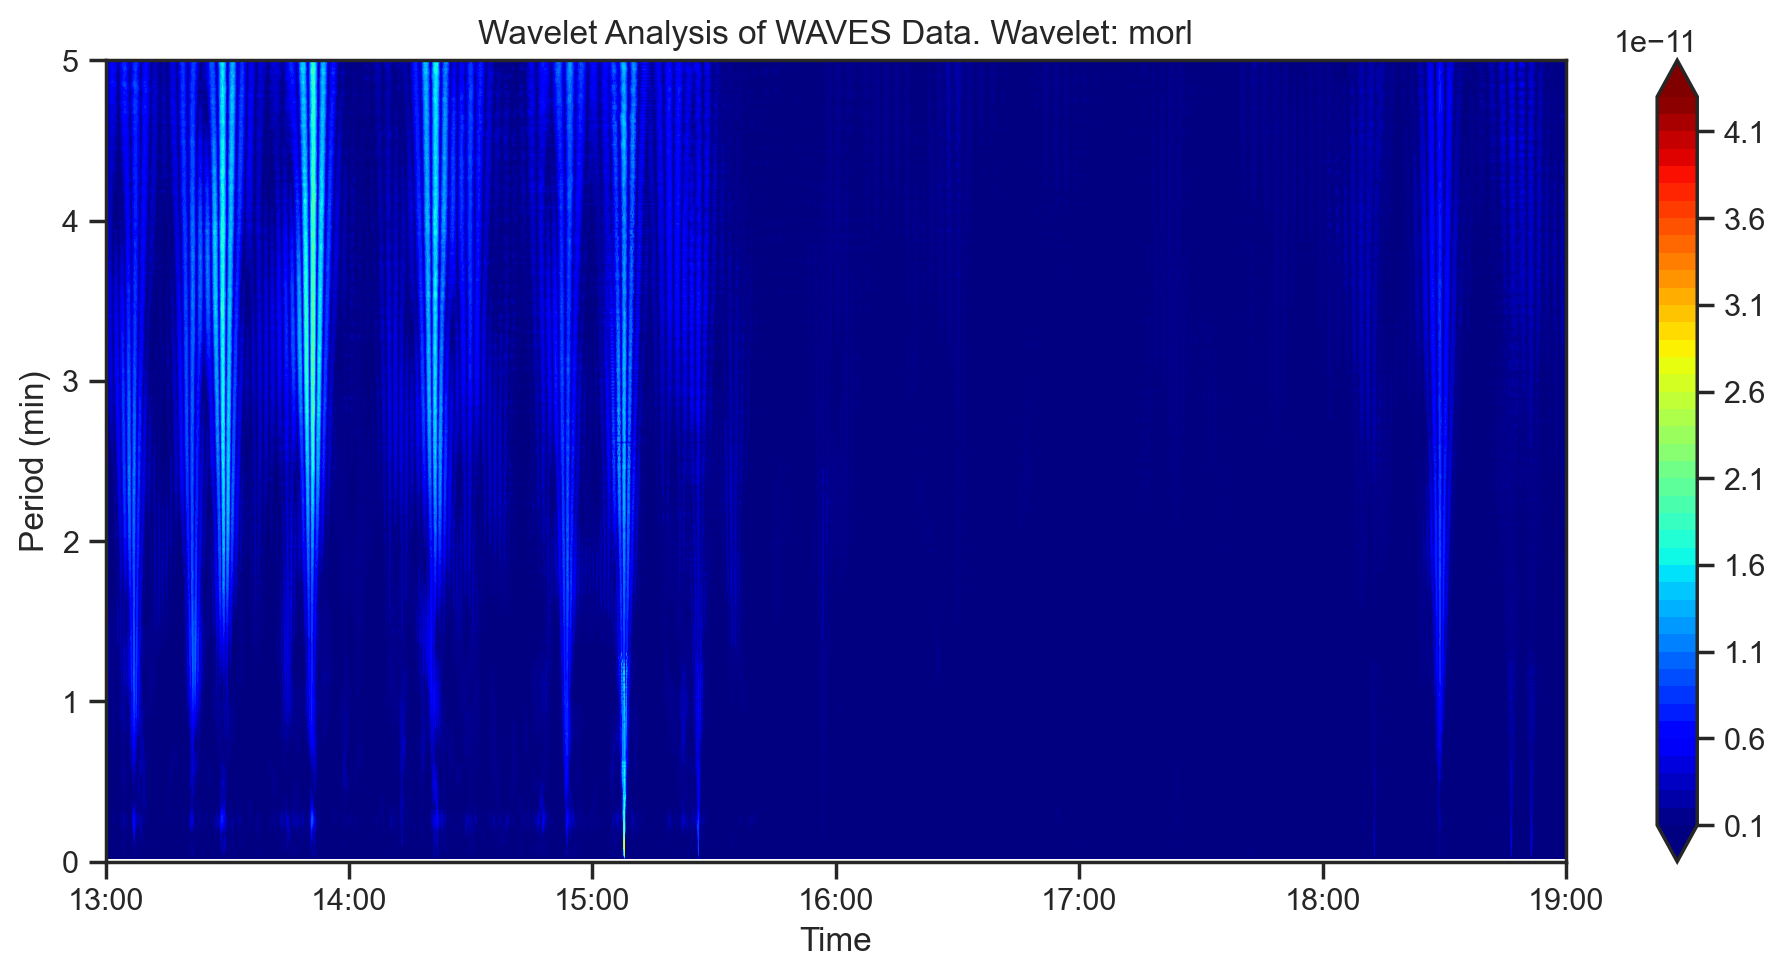

In [42]:
import pywt

wavelet = 'morl'

scales= np.arange(1,10*60,1)
[coefficients, frequencies] = pywt.cwt(waves.Radio, scales, wavelet, 1) # Radio Data, scale(range of values by how much youll squeeze or strech the wavelet by), wavelet shape, dt step (1sec)

power = (abs(coefficients))
period = (1/frequencies)/60 # mins

cmap='jet'
sns.set_theme(style='ticks')
fig, ax = plt.subplots(dpi=200, figsize=(10,5))
im = ax.contourf(waves['DateTime'], period, power, levels=50, extend='both', cmap=cmap)
cb = fig.colorbar(im)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.set_ylabel('Period (min)')
ax.set_xlabel('Time')
plt.tight_layout()
plt.ylim(0,5)
plt.title(rf'Wavelet Analysis of WAVES Data. Wavelet: {wavelet}')
plt.show()

/opt/anaconda3/lib/python3.11/site-packages/pywt/_cwt.py:121: FutureWarning: Wavelets from the family cmor, without parameters specified in the name are deprecated. The name should takethe form cmorB-C where B and C are floats representing the bandwidth frequency and center frequency, respectively (example: cmor1.5-1.0).
  wavelet = DiscreteContinuousWavelet(wavelet)


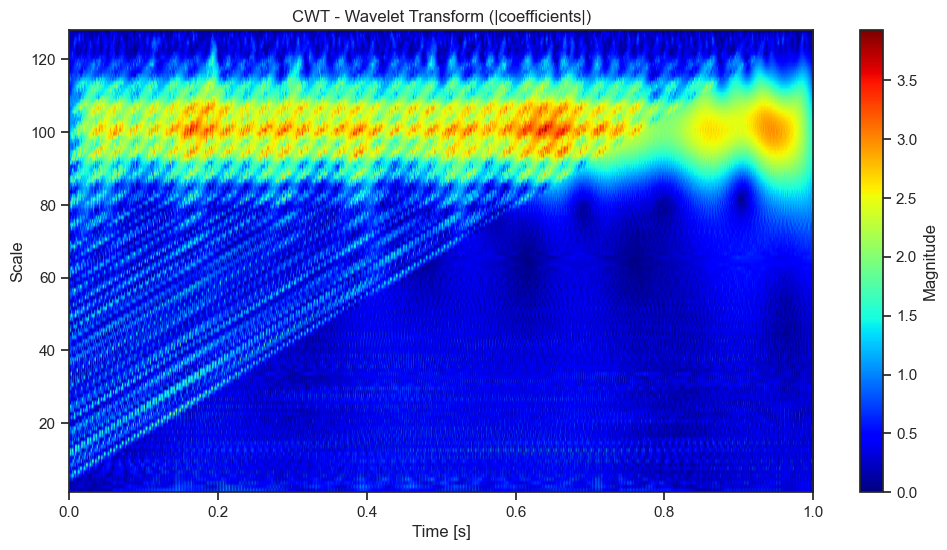

In [13]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

# Example signal: sinusoid + noise
t = np.linspace(0, 1, 1000)
signal = np.sin(20 * 2 * np.pi * t) + 0.5 * np.random.randn(t.size)

# Define scales and wavelet
scales = np.arange(1, 128)
waveletname = 'cmor'  # complex Morlet, good for time-frequency

# Perform CWT
coefficients, frequencies = pywt.cwt(signal, scales, waveletname, sampling_period=1/1000)

# Plot
plt.figure(figsize=(12, 6))
plt.imshow(np.abs(coefficients), extent=[0, 1, 1, 128], cmap='jet', aspect='auto',
           vmax=abs(coefficients).max(), vmin=0)
plt.colorbar(label='Magnitude')
plt.ylabel('Scale')
plt.xlabel('Time [s]')
plt.title('CWT - Wavelet Transform (|coefficients|)')
plt.show()
